# TA-06: Eksplorasi Mendalam Random Forest
## Klasifikasi Jenis Kacang Kering (Dry Bean) Berdasarkan Karakteristik Fisik

**Dataset:** Dry Bean Dataset (UCI ML Repository, id=602) — 13.611 sampel, 16 fitur geometri, 7 kelas (Barbunya, Bombay, Cali, Dermason, Horoz, Seker, Sira).
Koklu & Ozkan (2020), *Computers and Electronics in Agriculture*, 174, 105507. Lisensi CC BY 4.0.

**Alur:** Preprocessing → Skenario A (`n_estimators`) → Skenario B (`max_depth`) → Feature Importance → Evaluasi Akhir → Simpan model untuk web app.

In [1]:
import os, json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
os.makedirs('model', exist_ok=True); os.makedirs('figures', exist_ok=True)

In [2]:
%pip install openpyxl seaborn matplotlib scikit-learn joblib 

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Persiapan Data & Preprocessing
### 1.1 Load Data
Urutan pencarian: file lokal (`Dry_Bean_Dataset.xlsx` / `.csv`) → paket `ucimlrepo` (butuh internet).

In [3]:
def load_dry_bean():
    for f in ['Dry_Bean_Dataset.xlsx', 'DryBeanDataset/Dry_Bean_Dataset.xlsx']:
        if os.path.exists(f):
            return pd.read_excel(f)
    for f in ['Dry_Bean_Dataset.csv', 'dry_bean.csv']:
        if os.path.exists(f):
            return pd.read_csv(f)
    try:
        from ucimlrepo import fetch_ucirepo
        d = fetch_ucirepo(id=602)
        return pd.concat([d.data.features, d.data.targets], axis=1)
    except Exception as e:
        raise FileNotFoundError(
            'Dataset tidak ditemukan. Unduh dari https://archive.ics.uci.edu/dataset/602/dry+bean+dataset '
            'lalu letakkan Dry_Bean_Dataset.xlsx di folder notebook ini, atau jalankan: pip install ucimlrepo') from e

df = load_dry_bean().rename(columns={'AspectRation': 'AspectRatio'})
print(df.shape)
df.head()

(13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


### 1.2 Analisis Awal (kualitas data & class imbalance)

In [4]:
print('Missing values :', int(df.isna().sum().sum()))
print('Baris duplikat :', int(df.duplicated().sum()))
df.describe().T

Missing values : 0
Baris duplikat : 68


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRatio,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64
Persentase (%):
Class
DERMASON    26.05
SIRA        19.37
SEKER       14.89
HOROZ       14.17
CALI        11.98
BARBUNYA     9.71
BOMBAY       3.84
Name: count, dtype: float64

Rasio imbalance (mayoritas/minoritas): 6.79x


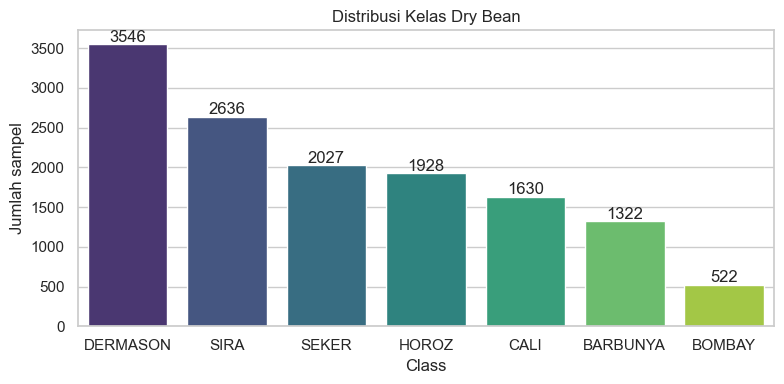

In [5]:
counts = df['Class'].value_counts()
print(counts)
print('Persentase (%):'); print((counts/len(df)*100).round(2))
print(f'\nRasio imbalance (mayoritas/minoritas): {counts.max()/counts.min():.2f}x')

fig, ax = plt.subplots(figsize=(8,4))
sns.barplot(x=counts.index, y=counts.values, palette='viridis', ax=ax)
for i,v in enumerate(counts.values): ax.text(i, v+30, str(v), ha='center')
ax.set_title('Distribusi Kelas Dry Bean'); ax.set_ylabel('Jumlah sampel')
plt.tight_layout(); plt.savefig('figures/class_distribution.png', dpi=150); plt.show()

### 1.3 Encoding & Split Data (80/20)
Target `Class` berupa kategori → di-*encode* dengan `LabelEncoder`. Seluruh fitur sudah numerik (tidak perlu One-Hot) dan Random Forest berbasis pohon sehingga **tidak memerlukan scaling**.
Split memakai `stratify=y` agar proporsi tiap kelas (terutama Bombay yang kecil) terjaga di train & test.

In [6]:
le = LabelEncoder()
y = le.fit_transform(df['Class'])
X = df.drop(columns='Class')
feature_names = X.columns.tolist()
print(dict(zip(le.classes_, le.transform(le.classes_))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print('Train:', X_train.shape, '| Test:', X_test.shape)

{'BARBUNYA': np.int64(0), 'BOMBAY': np.int64(1), 'CALI': np.int64(2), 'DERMASON': np.int64(3), 'HOROZ': np.int64(4), 'SEKER': np.int64(5), 'SIRA': np.int64(6)}
Train: (10888, 16) | Test: (2723, 16)


## 2. Eksperimen Hyperparameter
Selain akurasi training & testing (sesuai soal), saya menambahkan **5-fold Stratified CV pada data training** sebagai dasar memilih konfigurasi terbaik. Dengan begitu data testing tidak dipakai untuk memilih parameter (menghindari *data leakage* / pemilihan yang terlalu optimis).

### Skenario A — Pengaruh Jumlah Pohon (`n_estimators`)

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
n_list = [10, 50, 100, 200, 500]
rows = []
for n in n_list:
    t0 = time.time()
    m = RandomForestClassifier(n_estimators=n, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
    fit_time = time.time() - t0
    cv_scores = cross_val_score(RandomForestClassifier(n_estimators=n, random_state=RANDOM_STATE, n_jobs=-1),
                                X_train, y_train, cv=cv, n_jobs=-1)
    rows.append(dict(n_estimators=n,
                     train_acc=accuracy_score(y_train, m.predict(X_train)),
                     test_acc=accuracy_score(y_test, m.predict(X_test)),
                     cv_mean=cv_scores.mean(), cv_std=cv_scores.std(), fit_time_s=fit_time))
res_A = pd.DataFrame(rows)
res_A.round(4)

,n_estimators,train_acc,test_acc,cv_mean,cv_std,fit_time_s
0,10,0.9954,0.9130,0.9204,0.0043,0.3171
1,50,0.9998,0.9210,0.9245,0.0060,0.5406
2,100,1.0000,0.9218,0.9244,0.0049,1.0639
3,200,1.0000,0.9221,0.9242,0.0057,1.8921
4,500,1.0000,0.9218,0.9242,0.0064,4.7845


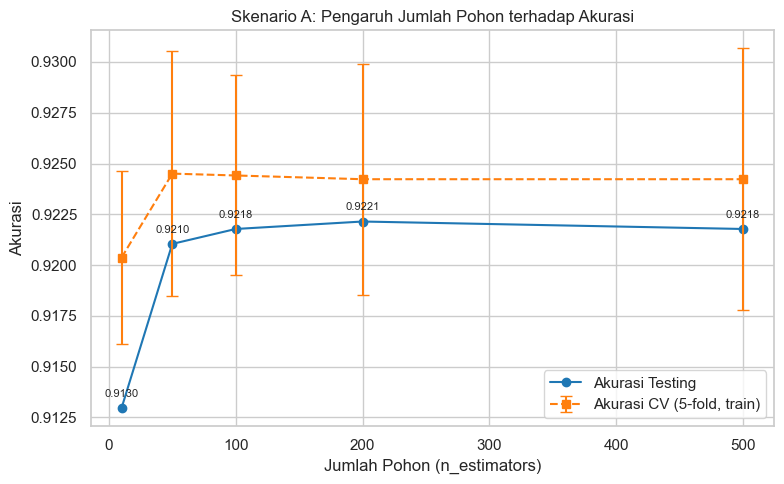

n_estimators terpilih: 50


In [8]:
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(res_A.n_estimators, res_A.test_acc, 'o-', label='Akurasi Testing', color='#1f77b4')
ax.errorbar(res_A.n_estimators, res_A.cv_mean, yerr=res_A.cv_std, fmt='s--', capsize=4,
            label='Akurasi CV (5-fold, train)', color='#ff7f0e')
for x,yv in zip(res_A.n_estimators, res_A.test_acc): ax.annotate(f'{yv:.4f}', (x,yv), textcoords='offset points', xytext=(0,8), ha='center', fontsize=8)
ax.set_xlabel('Jumlah Pohon (n_estimators)'); ax.set_ylabel('Akurasi')
ax.set_title('Skenario A: Pengaruh Jumlah Pohon terhadap Akurasi'); ax.legend()
plt.tight_layout(); plt.savefig('figures/skenario_A.png', dpi=150); plt.show()

# Pilih n terbaik berdasarkan CV; jika selisih <0.001 dari yang terbaik, pilih yang lebih kecil (lebih efisien)
best_cv = res_A.cv_mean.max()
best_n = int(res_A[res_A.cv_mean >= best_cv - 0.001].n_estimators.min())
print('n_estimators terpilih:', best_n)

**Analisis Skenario A** *(isi setelah menjalankan)*: apakah menambah pohon terus-menerus meningkatkan akurasi secara signifikan? Perhatikan titik di mana kurva mulai mendatar (*plateau*) dan bandingkan dengan kenaikan waktu training (`fit_time_s`).

### Skenario B — Pengaruh Kedalaman Pohon (`max_depth`)

In [9]:
depth_list = [None, 3, 5, 10, 20]
rows = []
for d in depth_list:
    m = RandomForestClassifier(n_estimators=best_n, max_depth=d, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
    cv_scores = cross_val_score(RandomForestClassifier(n_estimators=best_n, max_depth=d, random_state=RANDOM_STATE, n_jobs=-1),
                                X_train, y_train, cv=cv, n_jobs=-1)
    tr, te = accuracy_score(y_train, m.predict(X_train)), accuracy_score(y_test, m.predict(X_test))
    rows.append(dict(max_depth='None' if d is None else d, train_acc=tr, test_acc=te,
                     gap=tr-te, cv_mean=cv_scores.mean(), cv_std=cv_scores.std()))
res_B = pd.DataFrame(rows)
res_B.round(4)

,max_depth,train_acc,test_acc,gap,cv_mean,cv_std
0,None,0.9998,0.9210,0.0788,0.9245,0.0060
1,3,0.7853,0.7767,0.0086,0.7827,0.0026
2,5,0.8973,0.8843,0.0130,0.8889,0.0024
3,10,0.9651,0.9188,0.0463,0.9218,0.0056
4,20,0.9983,0.9236,0.0747,0.9221,0.0032


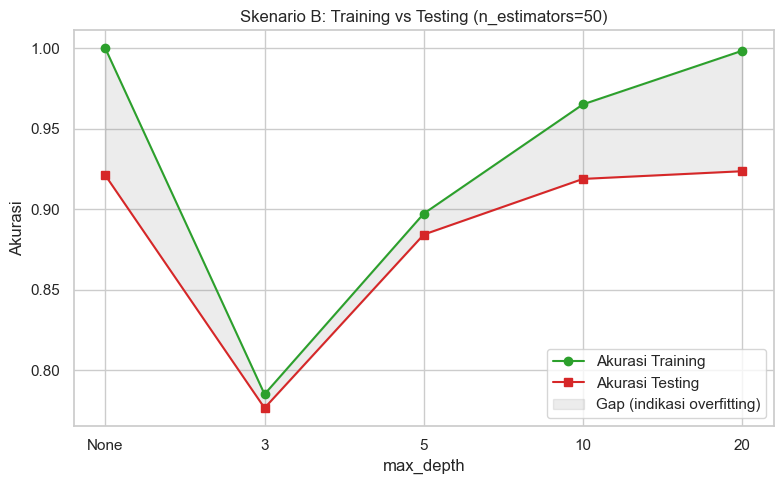

max_depth terpilih: None


In [10]:
labels = res_B.max_depth.astype(str).tolist()
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(labels, res_B.train_acc, 'o-', label='Akurasi Training', color='#2ca02c')
ax.plot(labels, res_B.test_acc, 's-', label='Akurasi Testing', color='#d62728')
ax.fill_between(range(len(labels)), res_B.test_acc, res_B.train_acc, alpha=.15, color='gray', label='Gap (indikasi overfitting)')
ax.set_xlabel('max_depth'); ax.set_ylabel('Akurasi')
ax.set_title(f'Skenario B: Training vs Testing (n_estimators={best_n})'); ax.legend()
plt.tight_layout(); plt.savefig('figures/skenario_B.png', dpi=150); plt.show()

best_cv_b = res_B.cv_mean.max()
cand = res_B[res_B.cv_mean >= best_cv_b - 0.001]
# pilih kedalaman paling dangkal di antara kandidat (model paling sederhana), None dianggap paling dalam
order = {str(d): i for i, d in enumerate(['3','5','10','20','None'])}
best_depth_str = min(cand.max_depth.astype(str), key=lambda s: order[s])
best_depth = None if best_depth_str == 'None' else int(best_depth_str)
print('max_depth terpilih:', best_depth)

**Analisis Skenario B** *(isi setelah menjalankan)*: pada kedalaman berapa gap Training–Testing mulai melebar? Catatan: Random Forest umumnya tetap mencapai training accuracy ≈ 1.0 pada `max_depth=None` — yang penting adalah apakah akurasi *testing/CV* ikut turun atau tetap stabil.

## 3. Model Terbaik & Evaluasi Akhir

In [11]:
best_model = RandomForestClassifier(n_estimators=best_n, max_depth=best_depth,
                                    random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
y_pred = best_model.predict(X_test)
acc = accuracy_score(y_test, y_pred); f1m = f1_score(y_test, y_pred, average='macro')
print(f'Konfigurasi: n_estimators={best_n}, max_depth={best_depth}')
print(f'Akurasi Testing: {acc:.4f} | Macro F1: {f1m:.4f}\n')
print(classification_report(y_test, y_pred, target_names=le.classes_, digits=4))

Konfigurasi: n_estimators=50, max_depth=None
Akurasi Testing: 0.9210 | Macro F1: 0.9330

              precision    recall  f1-score   support

    BARBUNYA     0.9400    0.8868    0.9126       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9358    0.9387    0.9372       326
    DERMASON     0.9069    0.9210    0.9139       709
       HOROZ     0.9661    0.9585    0.9623       386
       SEKER     0.9329    0.9581    0.9453       406
        SIRA     0.8640    0.8558    0.8599       527

    accuracy                         0.9210      2723
   macro avg     0.9351    0.9313    0.9330      2723
weighted avg     0.9211    0.9210    0.9209      2723



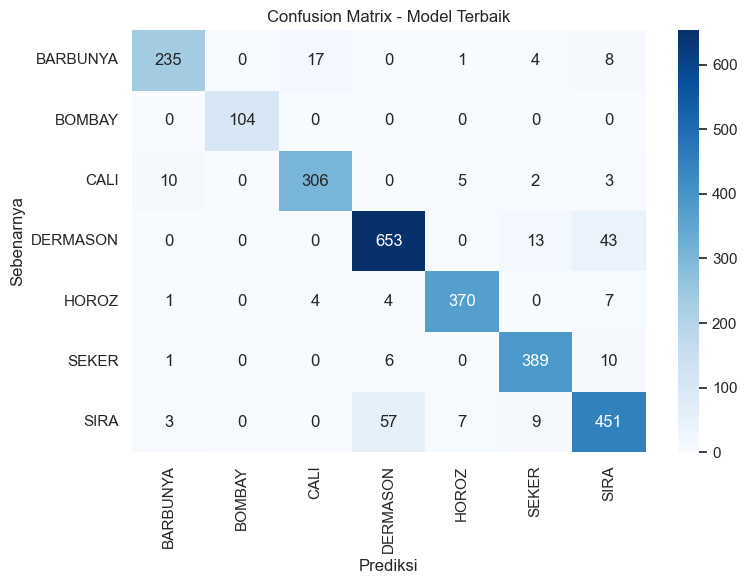

Top kesalahan (aktual -> prediksi):
  SIRA -> DERMASON: 57
  DERMASON -> SIRA: 43
  BARBUNYA -> CALI: 17
  DERMASON -> SEKER: 13
  CALI -> BARBUNYA: 10


In [12]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_, ax=ax)
ax.set_xlabel('Prediksi'); ax.set_ylabel('Sebenarnya'); ax.set_title('Confusion Matrix - Model Terbaik')
plt.tight_layout(); plt.savefig('figures/confusion_matrix.png', dpi=150); plt.show()

# Pasangan kelas yang paling sering tertukar
off = [(le.classes_[i], le.classes_[j], cm[i,j]) for i in range(len(cm)) for j in range(len(cm)) if i!=j]
print('Top kesalahan (aktual -> prediksi):')
for a,b,c in sorted(off, key=lambda t:-t[2])[:5]: print(f'  {a} -> {b}: {c}')

## 4. Analisis Feature Importance

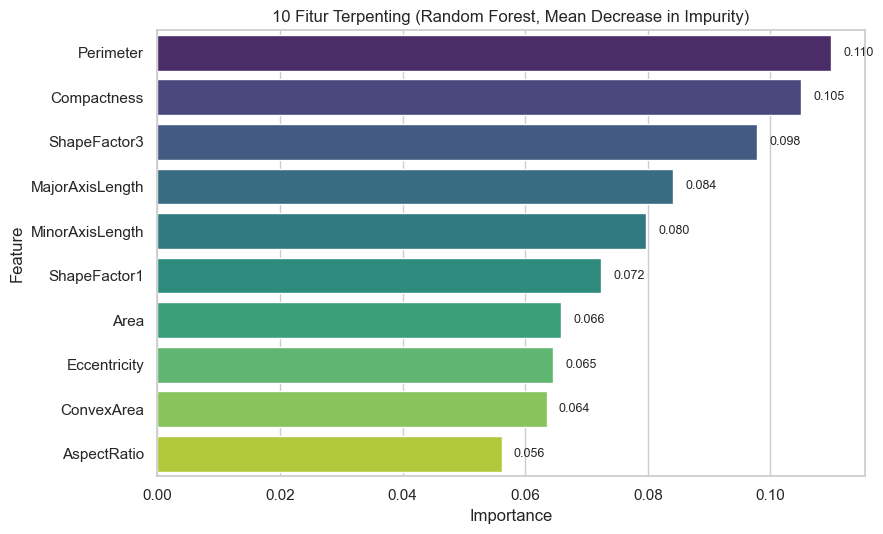

,Feature,Importance
0,Perimeter,0.1099
1,Compactness,0.1050
2,ShapeFactor3,0.0978
3,MajorAxisLength,0.0842
4,MinorAxisLength,0.0797
5,ShapeFactor1,0.0723
6,Area,0.0658
7,Eccentricity,0.0645
8,ConvexArea,0.0635
9,AspectRatio,0.0561


In [13]:
imp = pd.DataFrame({'Feature': feature_names, 'Importance': best_model.feature_importances_}) \
        .sort_values('Importance', ascending=False).reset_index(drop=True)
top10 = imp.head(10)
fig, ax = plt.subplots(figsize=(9,5.5))
sns.barplot(x='Importance', y='Feature', data=top10, palette='viridis', ax=ax)
for i,v in enumerate(top10.Importance): ax.text(v+0.002, i, f'{v:.3f}', va='center', fontsize=9)
ax.set_title('10 Fitur Terpenting (Random Forest, Mean Decrease in Impurity)')
plt.tight_layout(); plt.savefig('figures/feature_importance.png', dpi=150); plt.show()
imp.round(4)

**Catatan penting untuk interpretasi:** fitur dimensi (`Area`, `Perimeter`, `ConvexArea`, `EquivDiameter`, `MajorAxisLength`) saling berkorelasi sangat tinggi (multikolinearitas). Pada Random Forest, importance untuk fitur yang berkorelasi akan *terbagi* di antara mereka, sehingga nilai individual bisa tampak lebih kecil dari seharusnya. Cek korelasi dan permutation importance di bawah.

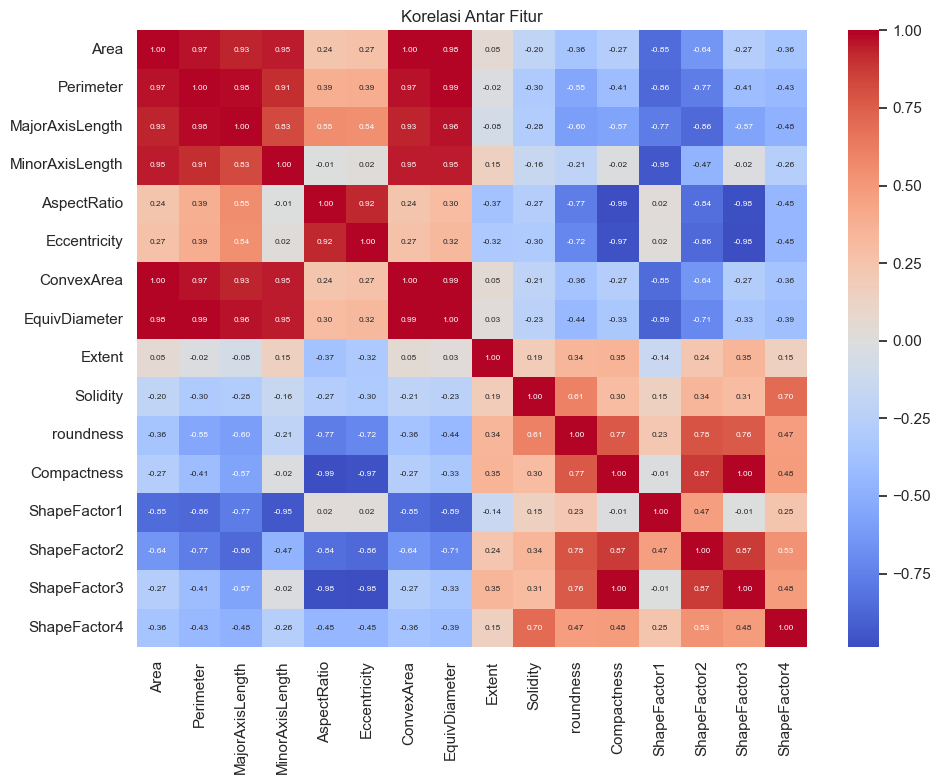

In [14]:
plt.figure(figsize=(10,8))
sns.heatmap(X.corr(), cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size':6})
plt.title('Korelasi Antar Fitur'); plt.tight_layout(); plt.savefig('figures/correlation.png', dpi=150); plt.show()

In [15]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
perm = pd.DataFrame({'Feature': feature_names, 'PermImportance': pi.importances_mean}) \
         .sort_values('PermImportance', ascending=False).head(10)
perm.round(4)

,Feature,PermImportance
10,roundness,0.0808
15,ShapeFactor4,0.0361
1,Perimeter,0.0083
11,Compactness,0.0060
14,ShapeFactor3,0.0035
12,ShapeFactor1,0.0034
2,MajorAxisLength,0.0030
9,Solidity,0.0027
7,EquivDiameter,0.0022
4,AspectRatio,0.0019


**Interpretasi** *(isi setelah menjalankan)*: jelaskan mengapa fitur-fitur teratas (mis. ukuran/bentuk seperti `ShapeFactor`, `MajorAxisLength`, `Compactness`) masuk akal untuk membedakan varietas — mis. Bombay berukuran sangat besar, Horoz berbentuk memanjang, Seker berbentuk bulat. Apakah sesuai intuisi domain?

## 5. Simpan Model untuk Deployment Web

In [16]:
joblib.dump(best_model, 'model/rf_dry_bean.joblib', compress=3)
import sklearn
meta = {
    'sklearn_version': sklearn.__version__,
    'feature_names': feature_names,
    'class_names': le.classes_.tolist(),
    'best_params': {'n_estimators': best_n, 'max_depth': best_depth},
    'test_accuracy': float(acc), 'macro_f1': float(f1m),
    'feature_min': X.min().to_dict(), 'feature_max': X.max().to_dict(),
    'feature_median': X.median().to_dict(),
    'class_median': {c: X[df['Class']==c].median().to_dict() for c in le.classes_},
    'feature_importance': imp.set_index('Feature')['Importance'].to_dict(),
}
json.dump(meta, open('model/metadata.json','w'), indent=2)
print('Tersimpan: model/rf_dry_bean.joblib, model/metadata.json')

Tersimpan: model/rf_dry_bean.joblib, model/metadata.json


## 6. Kesimpulan *(isi setelah menjalankan)*
- Konfigurasi terbaik & stabil: `n_estimators = ...`, `max_depth = ...`
- Akurasi testing / Macro F1: ...
- Kelas yang paling sulit dibedakan: ... (lihat confusion matrix)
- Fitur kunci: ...
- Business insight: ...